Episode   200 | avg reward (last 200):   -49.3 | avg steps:   59.5 | epsilon: 0.367
Episode   400 | avg reward (last 200):    74.3 | avg steps:   19.1 | epsilon: 0.135
Episode   600 | avg reward (last 200):    83.4 | avg steps:   15.4 | epsilon: 0.049
Episode   800 | avg reward (last 200):    85.7 | avg steps:   14.5 | epsilon: 0.018
Episode  1000 | avg reward (last 200):    86.7 | avg steps:   14.1 | epsilon: 0.010
Episode  1200 | avg reward (last 200):    86.6 | avg steps:   14.2 | epsilon: 0.010
Episode  1400 | avg reward (last 200):    86.6 | avg steps:   14.2 | epsilon: 0.010
Episode  1600 | avg reward (last 200):    86.6 | avg steps:   14.1 | epsilon: 0.010
Episode  1800 | avg reward (last 200):    86.6 | avg steps:   14.1 | epsilon: 0.010
Episode  2000 | avg reward (last 200):    86.7 | avg steps:   14.1 | epsilon: 0.010

Greedy path reached goal: True
Path length (steps): 14
Path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (5, 5), (6, 5), (

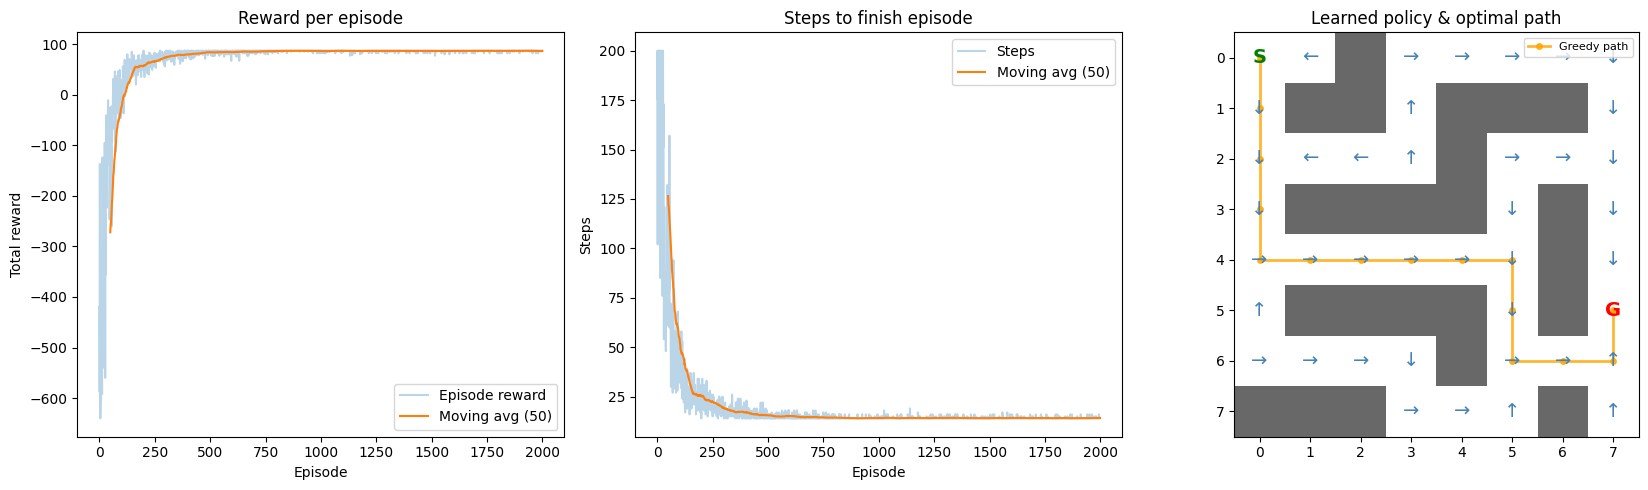

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------- Maze definition ----------------
# S = start, G = goal, # = wall, . = free cell
MAZE = [
    "S.#.....",
    ".##.###.",
    "....#...",
    ".####.#.",
    "......#.",
    ".####.#G",
    "....#...",
    "###...#.",
]

ACTIONS = ["UP", "DOWN", "LEFT", "RIGHT"]
DELTAS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ARROWS = ["↑", "↓", "←", "→"]

# ---------------- Hyperparameters ----------------
ALPHA = 0.1            # learning rate
GAMMA = 0.95           # discount factor
EPS_START, EPS_END = 1.0, 0.01
EPS_DECAY = 0.995      # per episode
EPISODES = 2000
MAX_STEPS = 200        # step cap per episode

# Rewards
R_GOAL = 100.0
R_STEP = -1.0          # small cost per move -> encourages shortest path
R_WALL = -5.0          # bumped into a wall / boundary

rng = np.random.default_rng(42)


class MazeEnv:
    def __init__(self, layout):
        self.grid = np.array([list(row) for row in layout])
        self.n_rows, self.n_cols = self.grid.shape
        self.start = tuple(int(v) for v in np.argwhere(self.grid == "S")[0])
        self.goal = tuple(int(v) for v in np.argwhere(self.grid == "G")[0])
        self.pos = self.start

    def reset(self):
        self.pos = self.start
        return self.pos

    def step(self, action):
        dr, dc = DELTAS[action]
        r, c = self.pos[0] + dr, self.pos[1] + dc

        # out of bounds or wall -> stay in place, penalty
        if not (0 <= r < self.n_rows and 0 <= c < self.n_cols) or self.grid[r, c] == "#":
            return self.pos, R_WALL, False

        self.pos = (r, c)
        if self.pos == self.goal:
            return self.pos, R_GOAL, True
        return self.pos, R_STEP, False


def choose_action(Q, state, epsilon):
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    q = Q[state]
    # break ties randomly so early greedy moves aren't biased toward "UP"
    return int(rng.choice(np.flatnonzero(q == q.max())))


def train(env):
    Q = np.zeros((env.n_rows, env.n_cols, len(ACTIONS)))
    epsilon = EPS_START
    rewards, steps_per_ep = [], []

    for ep in range(EPISODES):
        state = env.reset()
        total, steps, done = 0.0, 0, False

        while not done and steps < MAX_STEPS:
            action = choose_action(Q, state, epsilon)
            next_state, reward, done = env.step(action)

            # Q-learning (off-policy TD) update
            best_next = 0.0 if done else np.max(Q[next_state])
            td_target = reward + GAMMA * best_next
            Q[state][action] += ALPHA * (td_target - Q[state][action])

            state = next_state
            total += reward
            steps += 1

        epsilon = max(EPS_END, epsilon * EPS_DECAY)
        rewards.append(total)
        steps_per_ep.append(steps)

        if (ep + 1) % 200 == 0:
            print(f"Episode {ep + 1:5d} | avg reward (last 200): "
                  f"{np.mean(rewards[-200:]):7.1f} | avg steps: "
                  f"{np.mean(steps_per_ep[-200:]):6.1f} | epsilon: {epsilon:.3f}")

    return Q, rewards, steps_per_ep


def greedy_path(env, Q):
    """Follow the learned greedy policy from start to goal."""
    state = env.reset()
    path = [state]
    for _ in range(env.n_rows * env.n_cols):
        action = int(np.argmax(Q[state]))
        state, _, done = env.step(action)
        path.append(state)
        if done:
            return path, True
    return path, False


def moving_avg(x, w=50):
    return np.convolve(x, np.ones(w) / w, mode="valid")


def plot_results(env, Q, rewards, steps_per_ep, path):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    # 1) Learning curve
    axes[0].plot(rewards, alpha=0.3, label="Episode reward")
    axes[0].plot(range(49, len(rewards)), moving_avg(rewards), label="Moving avg (50)")
    axes[0].set(title="Reward per episode", xlabel="Episode", ylabel="Total reward")
    axes[0].legend()

    # 2) Steps per episode
    axes[1].plot(steps_per_ep, alpha=0.3, label="Steps")
    axes[1].plot(range(49, len(steps_per_ep)), moving_avg(steps_per_ep), label="Moving avg (50)")
    axes[1].set(title="Steps to finish episode", xlabel="Episode", ylabel="Steps")
    axes[1].legend()

    # 3) Maze with policy arrows and greedy path
    ax = axes[2]
    img = np.zeros((env.n_rows, env.n_cols))
    img[env.grid == "#"] = 1
    ax.imshow(img, cmap="Greys", vmin=0, vmax=1.5)

    for r in range(env.n_rows):
        for c in range(env.n_cols):
            if env.grid[r, c] == "#":
                continue
            if (r, c) == env.start:
                ax.text(c, r, "S", ha="center", va="center", color="green", fontsize=14, fontweight="bold")
            elif (r, c) == env.goal:
                ax.text(c, r, "G", ha="center", va="center", color="red", fontsize=14, fontweight="bold")
            elif Q[r, c].max() != 0:
                ax.text(c, r, ARROWS[int(np.argmax(Q[r, c]))], ha="center", va="center",
                        color="steelblue", fontsize=14)

    ys, xs = zip(*path)
    ax.plot(xs, ys, "o-", color="orange", linewidth=2, markersize=4, alpha=0.8, label="Greedy path")
    ax.set_xticks(range(env.n_cols))
    ax.set_yticks(range(env.n_rows))
    ax.set_title("Learned policy & optimal path")
    ax.legend(loc="upper right", fontsize=8)

    plt.tight_layout()
    plt.savefig("qlearning_maze_results.png", dpi=150)
    print("Saved plot to qlearning_maze_results.png")
    plt.show()


if __name__ == "__main__":
    env = MazeEnv(MAZE)
    Q, rewards, steps_per_ep = train(env)

    path, reached = greedy_path(env, Q)
    print("\nGreedy path reached goal:", reached)
    print("Path length (steps):", len(path) - 1)
    print("Path:", path)

    plot_results(env, Q, rewards, steps_per_ep, path)